# Procesiranje slik za meritve v strukturni dinamiki

---

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Slikovne-meritve" data-toc-modified-id="Slikovne-meritve-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Slikovne meritve</a></span><ul class="toc-item"><li><span><a href="#Parametri-zajema" data-toc-modified-id="Parametri-zajema-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>Parametri zajema</a></span></li><li><span><a href="#Osvetlitev" data-toc-modified-id="Osvetlitev-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>Osvetlitev</a></span></li><li><span><a href="#Priprava-površine-merjenca" data-toc-modified-id="Priprava-površine-merjenca-1.3"><span class="toc-item-num">1.3&nbsp;&nbsp;</span>Priprava površine merjenca</a></span></li><li><span><a href="#Pogoste-težave-pri-slikovnih-meritvah" data-toc-modified-id="Pogoste-težave-pri-slikovnih-meritvah-1.4"><span class="toc-item-num">1.4&nbsp;&nbsp;</span>Pogoste težave pri slikovnih meritvah</a></span><ul class="toc-item"><li><span><a href="#Neustrezno-izostrena-slika" data-toc-modified-id="Neustrezno-izostrena-slika-1.4.1"><span class="toc-item-num">1.4.1&nbsp;&nbsp;</span>Neustrezno izostrena slika</a></span></li><li><span><a href="#Neustrezna-osvetlitev" data-toc-modified-id="Neustrezna-osvetlitev-1.4.2"><span class="toc-item-num">1.4.2&nbsp;&nbsp;</span>Neustrezna osvetlitev</a></span></li></ul></li></ul></li><li><span><a href="#Določitev-pomikov-na-slikah-z-metodo-optičnega-toka-(Simplified-Optical-Flow)" data-toc-modified-id="Določitev-pomikov-na-slikah-z-metodo-optičnega-toka-(Simplified-Optical-Flow)-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Določitev pomikov na slikah z metodo optičnega toka (<em>Simplified Optical Flow</em>)</a></span></li><li><span><a href="#Metoda-Lucas-Kanade:" data-toc-modified-id="Metoda-Lucas-Kanade:-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Metoda Lucas-Kanade:</a></span></li><li><span><a href="#Izračun-FRF" data-toc-modified-id="Izračun-FRF-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Izračun FRF</a></span></li><li><span><a href="#Eskperimentalna-modalna-analiza-(samo-slikovn-meritev):" data-toc-modified-id="Eskperimentalna-modalna-analiza-(samo-slikovn-meritev):-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Eskperimentalna modalna analiza (samo slikovn meritev):</a></span></li><li><span><a href="#Eskperimentalna-modalna-analiza---hibridna-metoda" data-toc-modified-id="Eskperimentalna-modalna-analiza---hibridna-metoda-6"><span class="toc-item-num">6&nbsp;&nbsp;</span>Eskperimentalna modalna analiza - hibridna metoda</a></span></li></ul></div>

Vsi potrebni paketi so navedeni v `requirements.txt`:
* ``pip install -m requirements.txt``

Priprava paketov in nekaterih funkcij:

In [1]:
import warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np

import matplotlib.pyplot as plt
import matplotlib.patches as patches

from orodja import plot_mode_shape
from ipywidgets import interact

import lvm_read
import pyidi
from sdypy import EMA as pyEMA
from sdypy import FRF as pyFRF

## Slikovne meritve

**Postavitev eksperimenta:**

<img src="figures/experiment_setup.jpg" width="80%">

**Vzbujanje z modalnim kladivom:**

<video controls loop src="figures/experiment.mp4" width="100%" rotate="270deg"/>

Datoteke s slikami:

In [2]:
cam_fname = 'data/camera.cih'
lvm_fname = 'data/acceleration.lvm'

Odpiranje posnetka s paketom [pyidi][1]:

[1]: https://github.com/ladisk/pyidi

In [3]:
video = pyidi.video_reader.VideoReader(cam_fname)

In [5]:
frames = video.get_frames() # (N, h, w)
frames.shape, frames.dtype 

((3750, 40, 640), dtype('uint8'))

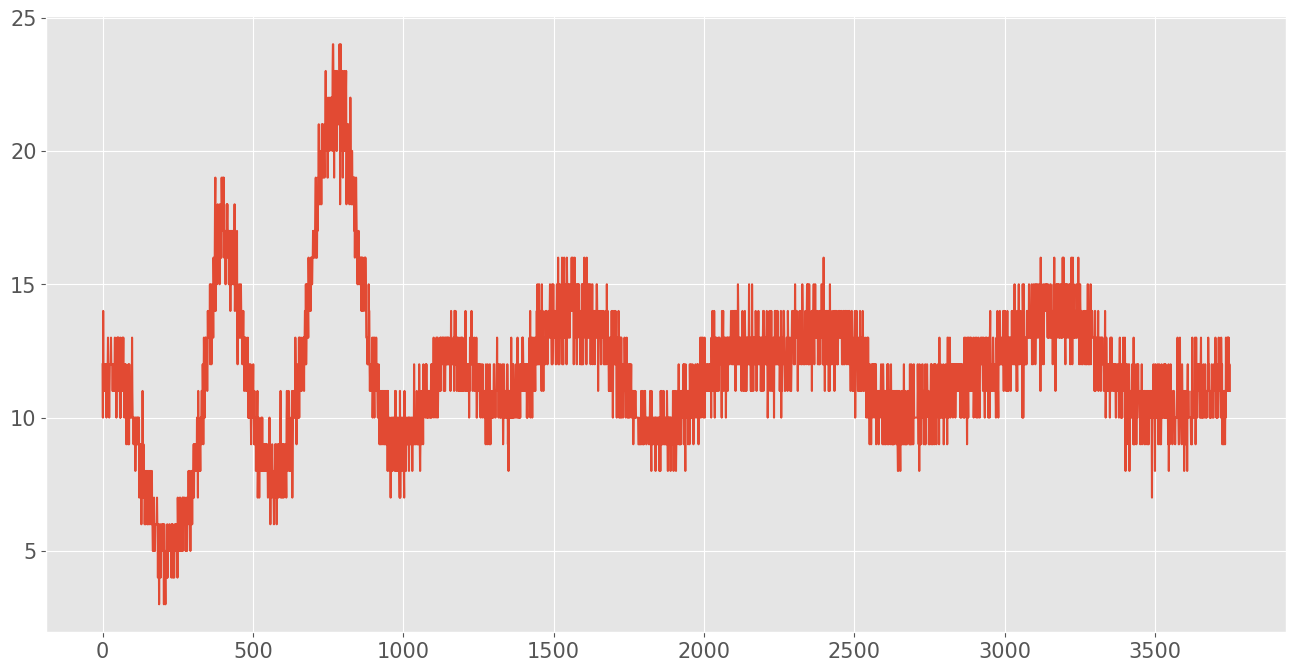

In [6]:
plt.plot(frames[:, 25, 200])

In [8]:
frames.shape

(3750, 40, 640)

In [11]:
frames.shape[1] * frames.shape[2] * 12 / 8 * 20000 / 1e6

768.0

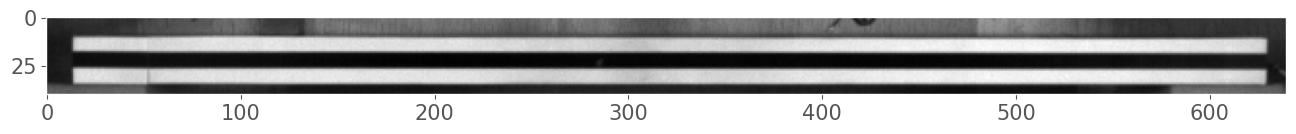

In [12]:
image_nr = 200
plt.figure()
plt.imshow(frames[image_nr], cmap='gray')
plt.grid(False)
plt.show()

*Posnetek je prilagojen prikazu in je zato slabše kavlaitete. Za natančne meritve običajno zajamemo zelo veliko količino podatkov.*

<video controls loop src="figures/video.mov" width="950" rotate="270deg"/>

### Parametri zajema

Parametri nastavitve kamere so zapisani v atributu `info`:

In [14]:
video.info['Color Bit']

8

### Osvetlitev

Ustrezna osvetlitev je eden najpomembnejših parametrov pri zajemu slik s hitro kamero.

Pri oceni ustreznosti osvetlitve si lahko pomagamo s hitrogramom sivinskih vrendosti:

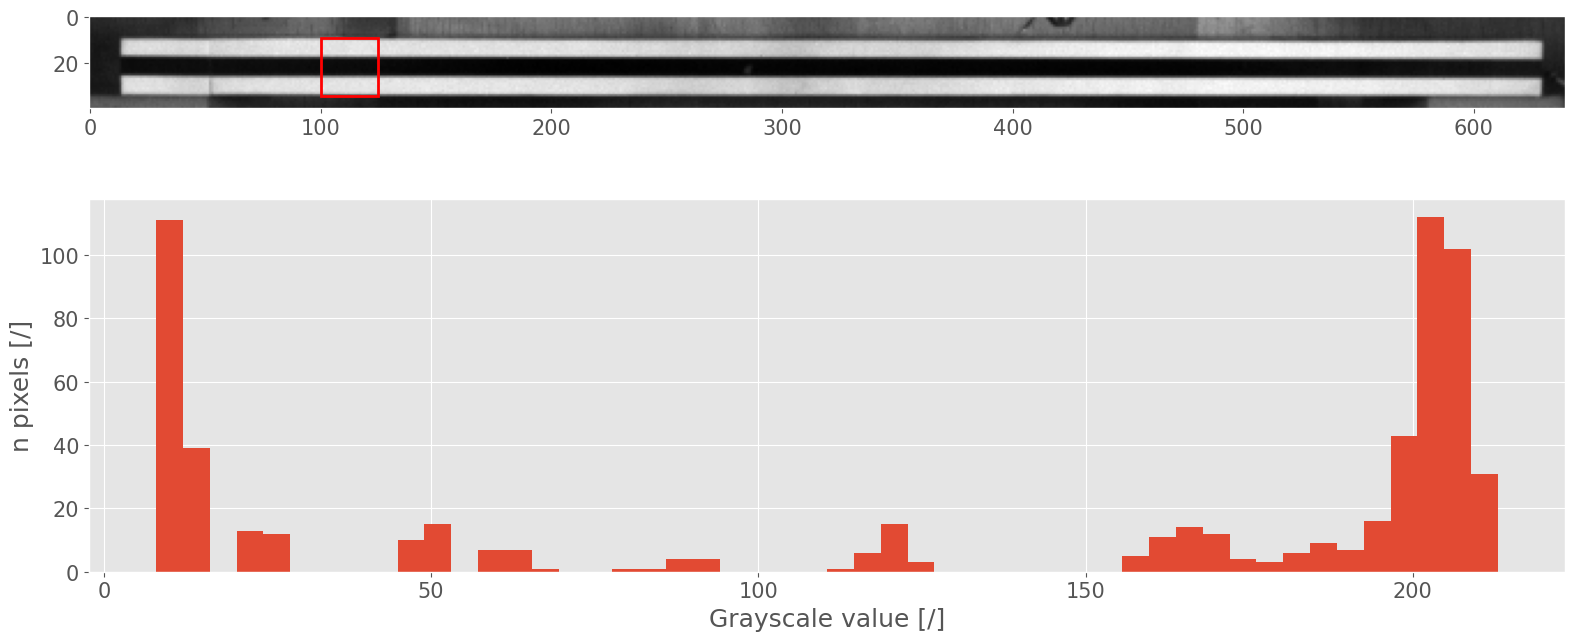

In [15]:
selected_frame = 0
x0 = 100 # position of observed rectangle
y0 = 9
d = 25
roi = frames[selected_frame, y0:y0+d, x0:x0+d]

fig, ax = plt.subplots(2)
ax[0].imshow(frames[selected_frame], cmap='gray')
ax[1].hist(roi.flatten(), bins=50);

# Formating
ax[0].add_patch(patches.Rectangle((x0, y0), d, d, fill=False, color='r', linewidth=2))
ax[0].grid(False)
ax[1].set_xlabel('Grayscale value [/]')
ax[1].set_ylabel('n pixels [/]')
plt.tight_layout()

### Priprava površine merjenca

Za delovanje metod določanja pomikov s slik na osnovi gradientov sivinskih vrendosti je nujno, da je površina merjenca ustrezno pripravljena. 

Pogosto na opazovano površino apliciramo visokokontrasntni vzorec pack (*speckle*) ali črt. Identifikacija pomikov je najzaneslivejša v smeri gradienta sivinskih vrendosti.

In [17]:
frames[0].shape

(40, 640)

In [19]:
grad0, grad1 = np.gradient(frames[0].astype(float)) # gradient computation

In [24]:
grad0.shape

(40, 640)

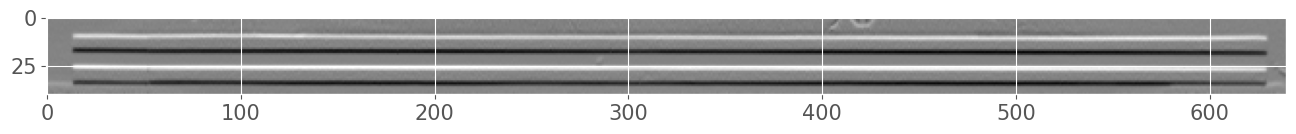

In [25]:
plt.figure()
plt.imshow(grad0, cmap='gray')

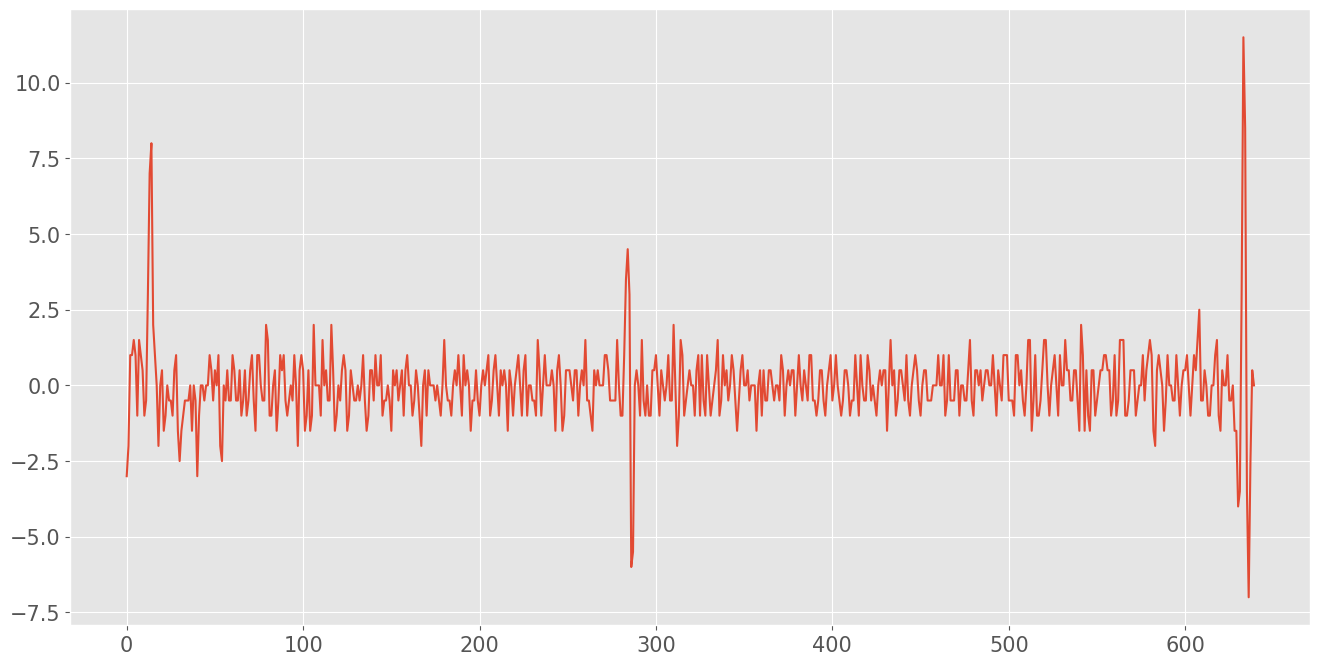

In [20]:
plt.plot(grad1[25])

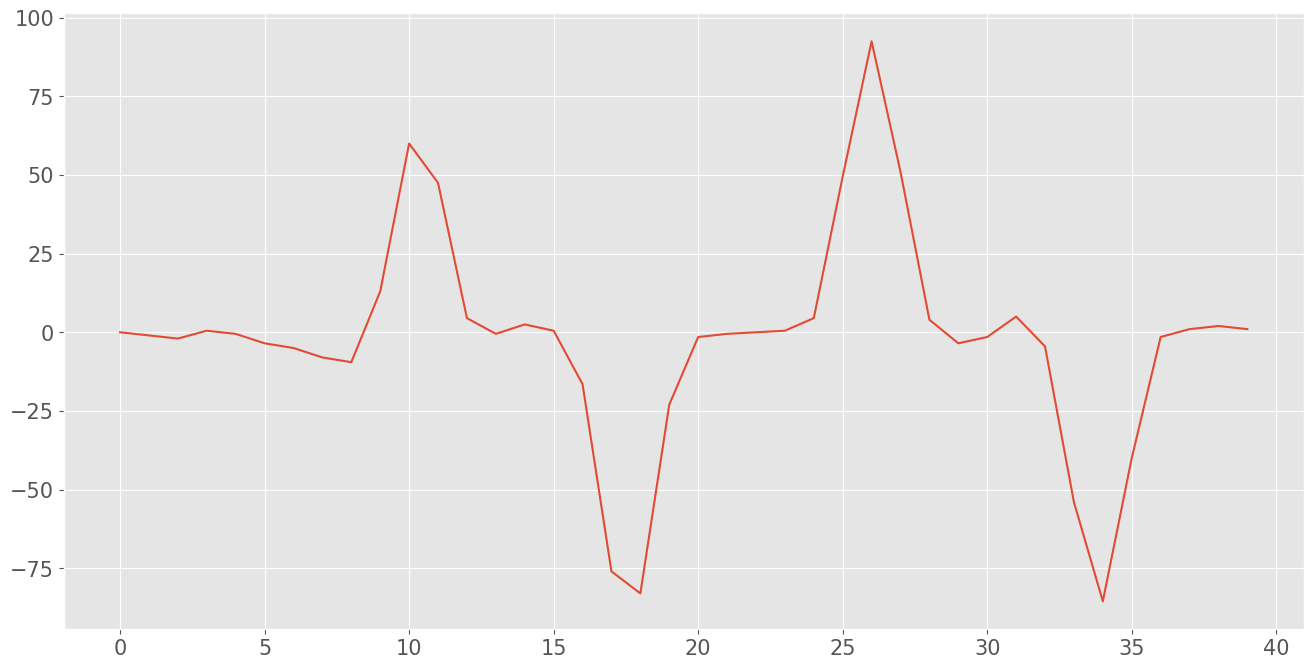

In [21]:
plt.plot(grad0[:, 200])

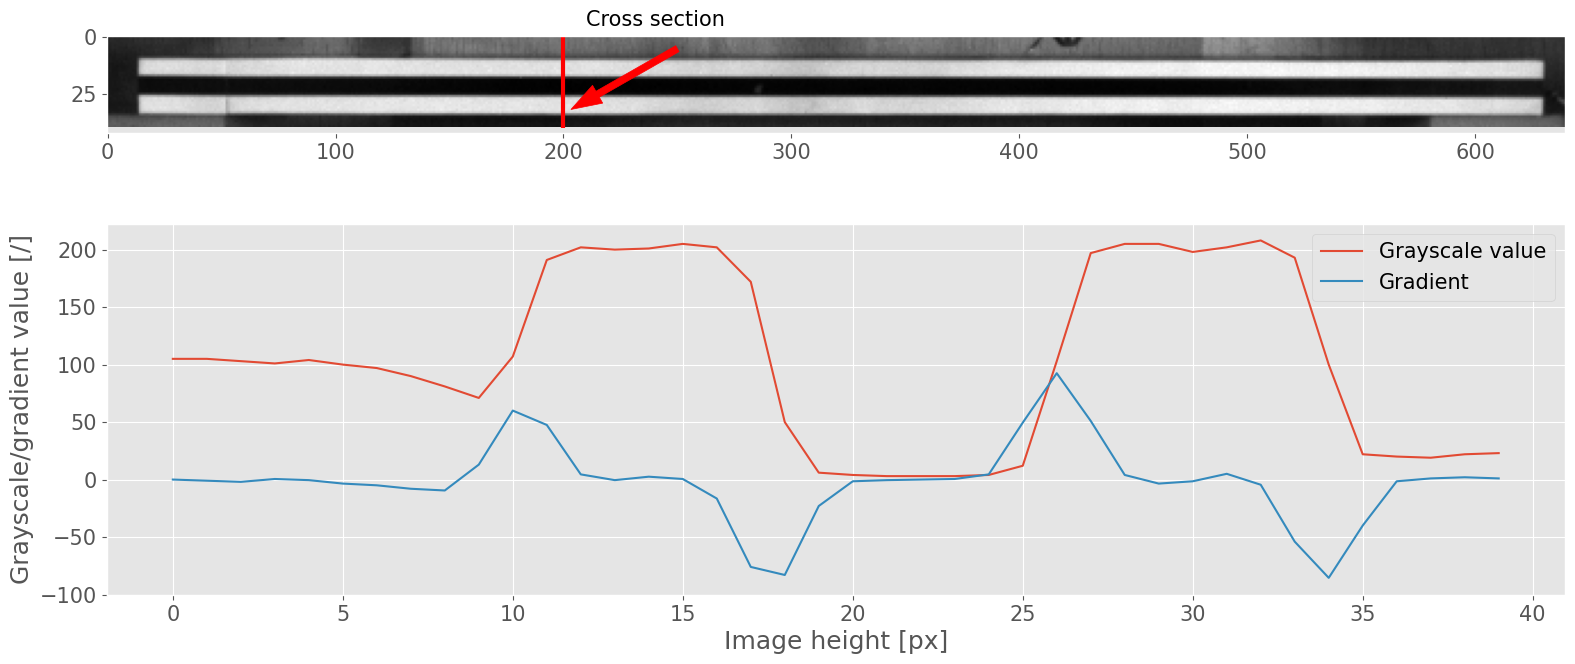

In [22]:
x0 = 200 # position of cross section

fig, ax = plt.subplots(2)
ax[0].imshow(video.get_frames()[selected_frame], cmap='gray')
ax[1].plot(video.get_frames()[selected_frame, :, x0], label='Grayscale value')
ax[1].plot(grad0[:, x0], label='Gradient')
# Formating
ax[0].vlines(x0, 0, 40, colors='r', linewidth=3)
ax[0].text(x0+10, -5, 'Cross section')
ax[0].arrow(x0+50, 5, -35, 20, color='r', width=3)
ax[0].grid(False)
ax[1].set_xlabel('Image height [px]')
ax[1].set_ylabel('Grayscale/gradient value [/]')
plt.legend()
plt.tight_layout();

### Pogoste težave pri slikovnih meritvah

#### Neustrezno izostrena slika

In [27]:
layout_fname = r'data/focus.cih'
video_layout = pyidi.video_reader.VideoReader(layout_fname)

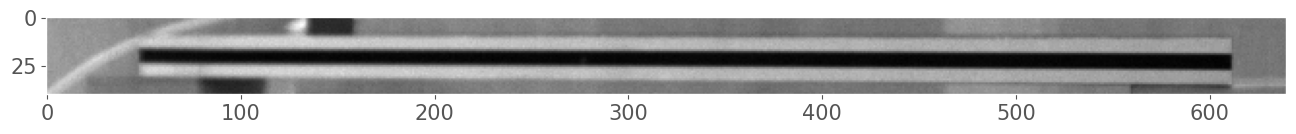

In [29]:
plt.imshow(video_layout.get_frames()[0], cmap='gray')
plt.grid(False)

#### Neustrezna osvetlitev

In [30]:
light_fname = r'data/illumination.cih'
video_light = pyidi.video_reader.VideoReader(light_fname)

In [31]:
%matplotlib ipympl

In [33]:
selected_frame = 0
y0, d = 9, 20

def show(x0):
    roi = video_light.get_frames()[selected_frame, y0:y0+d, x0:x0+d*2]
    fig, ax = plt.subplots(2)
    ax[0].imshow(video_light.get_frames()[selected_frame], cmap='gray')
    ax[1].hist(roi.flatten(), bins=50);
    # Formating
    ax[0].add_patch(patches.Rectangle((x0, y0), d*2, d, fill=False, color='r', linewidth=2))
    ax[0].grid(False)
    ax[1].set_xlabel('Grayscale value [/]')
    ax[1].set_ylabel('n pixels [/]')
    ax[1].set_xlim([0, 260])
    plt.tight_layout()
    plt.show()
interact(show, x0=100);

interactive(children=(IntSlider(value=100, description='x0', max=300, min=-100), Output()), _dom_classes=('wid…

In [34]:
%matplotlib inline

---

## Določitev pomikov na slikah z metodo optičnega toka

Svetlost na sliki se ohranja:
$$
	f(x, y, t) = f(x + \Delta x, y + \Delta y, t+ \Delta t).
$$

Sledi enačba poenostavljene metode optičnega toka za posamezno točko na sliki:
$$
s(x_j,y_k,t)=\frac{f_0(x_j,y_k)-f(x_j,y_k,t)}{|\nabla f_0|}
$$

$s(x_j,y_k,t) \dots$ pomik točke v smeri lokalnega gadienta sivinskih vrednosti

([Javh et al][1])

[1]: http://lab.fs.uni-lj.si/ladisk/?what=abstract&ID=179

Računamo pomike glede na referenčno sliko:

In [35]:
reference_image = np.average(video.get_frames()[:10], axis=0)

Potrebujemo slike gradienta v smeri ``x`` (1) in ``y`` (0):

In [36]:
grad0, grad1 = np.gradient(reference_image)

In [37]:
G = np.sqrt(grad0**2 + grad1**2)

Za obdelavo so primerne točke z visoko vrednostjo gradienta:

In [39]:
border = 20
border_h = 12

n = 2   # število vrstic mreže točk
N = 16  # število stolpcev mreže točk

w = np.arange(border, reference_image.shape[1]-border, np.abs(border - reference_image.shape[1]-border)//N) # stolpci mreže točk
h = np.argsort(np.abs(grad0[border_h:-border_h, w]), axis=0)[-n:, :].T + border_h # vrstice mreže točk - z najvišjo absolutno vrednostjo gradienta

inds = np.column_stack((h.flatten(), w.repeat(n)))

In [40]:
inds

array([[ 26,  20],
       [ 17,  20],
       [ 17,  60],
       [ 26,  60],
       [ 18, 100],
       [ 26, 100],
       [ 18, 140],
       [ 26, 140],
       [ 18, 180],
       [ 26, 180],
       [ 18, 220],
       [ 26, 220],
       [ 18, 260],
       [ 26, 260],
       [ 18, 300],
       [ 26, 300],
       [ 18, 340],
       [ 26, 340],
       [ 18, 380],
       [ 26, 380],
       [ 26, 420],
       [ 18, 420],
       [ 26, 460],
       [ 18, 460],
       [ 26, 500],
       [ 18, 500],
       [ 26, 540],
       [ 18, 540],
       [ 27, 580],
       [ 18, 580]])

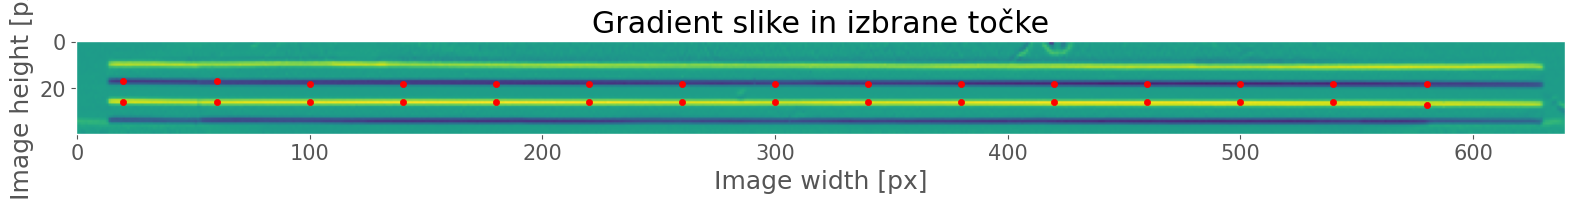

In [42]:
plt.figure()
plt.imshow(grad0, cmap='viridis')
plt.scatter(inds[:, 1], inds[:, 0], color='r', s=20)
plt.grid(False)
plt.xlabel('Image width [px]')
plt.ylabel('Image height [px]')
plt.title('Gradient slike in izbrane točke')
plt.tight_layout()
plt.show()

In [43]:
inds.shape

(30, 2)

In [44]:
rows, columns = inds.T
frames = video.get_frames()

Enačba optičnega toka:

$$
s(x_j,y_k,t)=\frac{f_0(x_j,y_k)-f(x_j,y_k,t)}{|\nabla f_0|}
$$


In [45]:
d_of = ((reference_image[rows, columns] - frames[:, rows, columns]) / np.abs(G[rows, columns])).T
d_of.shape

(30, 3750)

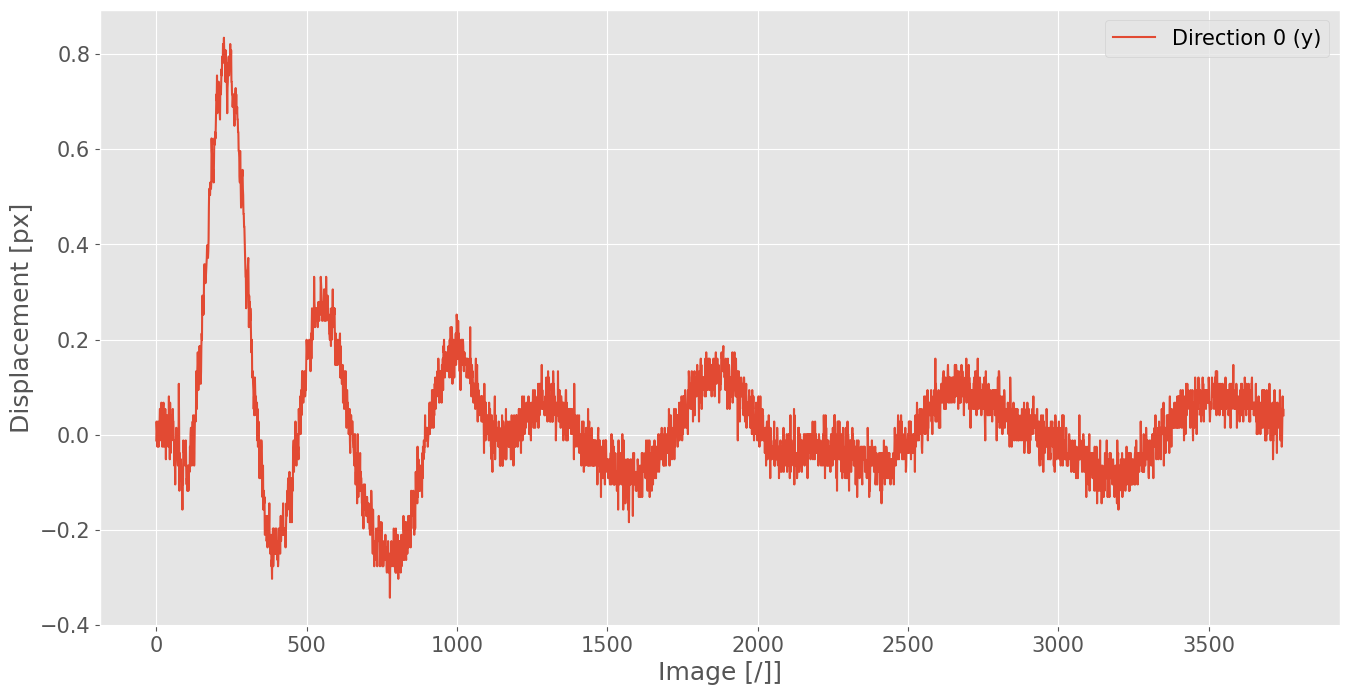

In [47]:
fig, ax = plt.subplots()
ax.plot(d_of[0], label='Direction 0 (y)');
ax.set_xlabel('Image [/]]')
ax.set_ylabel('Displacement [px]')
plt.legend()

Izračun pomikov s ``pyidi``:

In [49]:
sof_analiza = pyidi.SimplifiedOpticalFlow(video) # ustvari objekt za analizo
sof_analiza.set_points(points=inds) # izbira točk za analizo
sof_analiza.configure(mean_n_neighbours=2) # povprečimo sosednji dve točki (v istem stolpcu)

Izračun pomikov z ``get_displacements()``:

In [50]:
displacements = sof_analiza.get_displacements() * 8e-5 # pretvorba [piksel] > [m]

100%|█████████████████████████████████████████████████████████| 3750/3750 [00:01<00:00, 1944.07it/s]

Averaging...
Finished!



/mnt/data/pedagoško/_Procesiranje signalov/_VAJE/_PREDLOGE/.venv/lib/python3.13/site-packages/pyidi/methods/_simplified_optical_flow.py:155: UserWarning: Displacement larger than 0.5 pixel
  warnings.warn('Displacement larger than 0.5 pixel')


In [51]:
displacements.shape

(15, 3750, 2)

In [52]:
location = 1

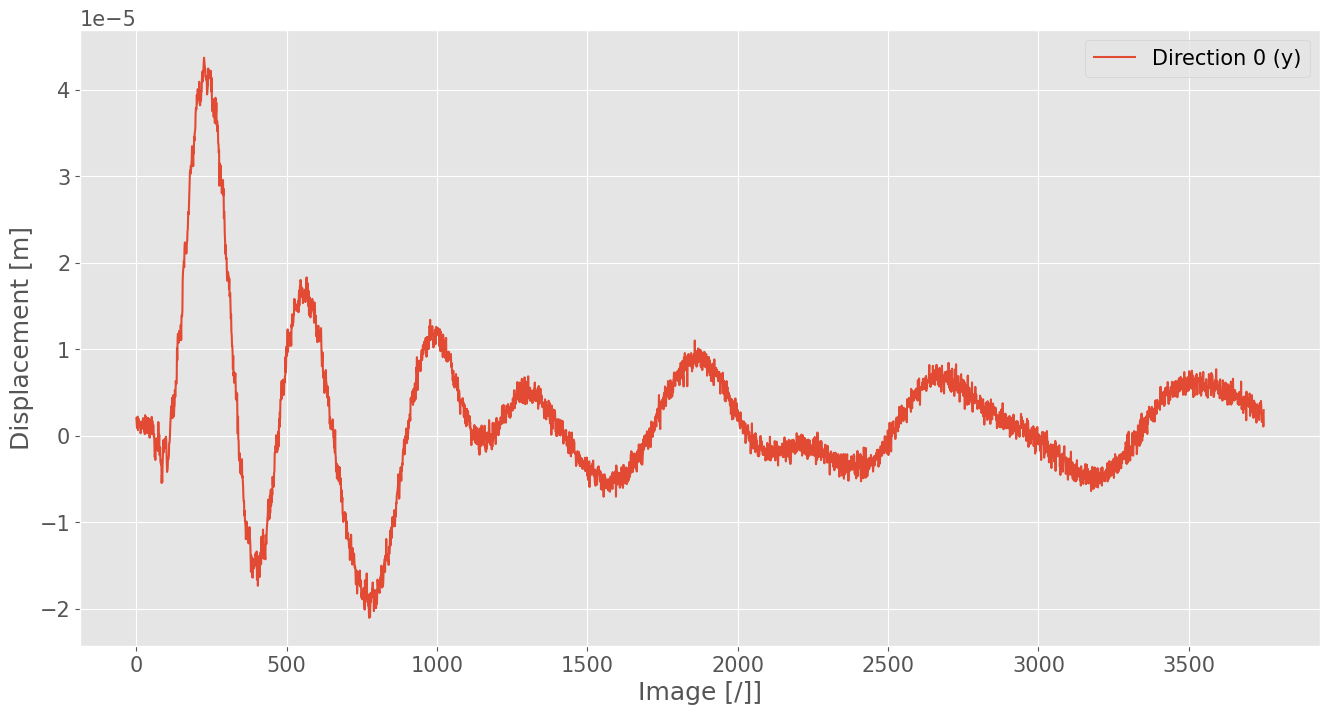

In [53]:
fig, ax = plt.subplots()
ax.plot(displacements[location, :, 0], label='Direction 0 (y)');
ax.set_xlabel('Image [/]]')
ax.set_ylabel('Displacement [m]')
plt.legend()

## Metoda Lucas-Kanade:

Če enačbe optičnega toka zapišemo za podobmočje več točk na sliki, dobimo predoločen sistem enačb.

Rešitev predoločenega sistema v smislu najmanjše kvadratične napake nam da pomik podobmočja:

$$
\begin{equation}
	\begin{bmatrix}
		\Delta x \\
		\Delta y
	\end{bmatrix} =
	\begin{bmatrix}
		\sum g_x^2 &\sum  g_x \, g_y \\
		\sum  g_x \, g_y &\sum g_y^2
	\end{bmatrix}^{-1}
	\begin{bmatrix}
		\sum g_x \, (f-g) \\
		\sum g_y \, (f-g)
	\end{bmatrix}
\end{equation}
$$


$f(\mathbf{x}) \dots$ trenutna (premaknjena) slika

$g(\mathbf{x}) \dots$ referenčna slika

Do enake rešitve pridemo, če rešim opzimizacijski problem, v katerem iščemo parametre $\Delta \mathbf{x}$, ki premaknjeno trenutno sliko $f(\mathbf{x} + \Delta \mathbf{x})$ poravnajo z referenčno $g(\mathbf{x})$:

$$
SSD(\Delta \mathbf{x}) = \sum\limits_{x, y} \big[f(\mathbf{x} + \Delta \mathbf{x}) - g(\mathbf{x})\big]^2.
$$


In [54]:
points_lk = np.column_stack([np.ones_like(w)*video.info['Image Height']//2, w])

In [55]:
lk_analiza = pyidi.LucasKanade(video) # ustvari objekt za analizo z metodo Lucas-Kanade
lk_analiza.set_points(points_lk)
lk_analiza.configure(roi_size=(21, 23), max_nfev=10, int_order=3)

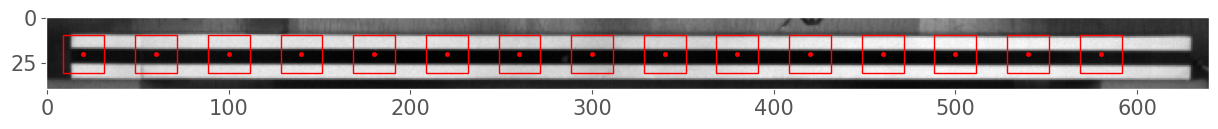

In [57]:
lk_analiza.show_points()

Izrčaun pomikov:

In [58]:
displacements_lk = lk_analiza.get_displacements(processes=2) * 8e-5

Output()

/home/dgorjup/.local/share/uv/python/cpython-3.13.9-linux-x86_64-gnu/lib/python3.13/multiprocessing/popen_fork.py:6
7: DeprecationWarning: This process (pid=854592) is multi-threaded, use of fork() may lead to deadlocks in the 
child.
  self.pid = os.fork()

--- Starting new analysis ---
 
Computation start: 2026-05-26 13:16:51.974550


Computation duration: 00:00:44.02


In [ ]:
displacements_lk = np.load('data/displacements_lk.npy')

In [59]:
točka = 1

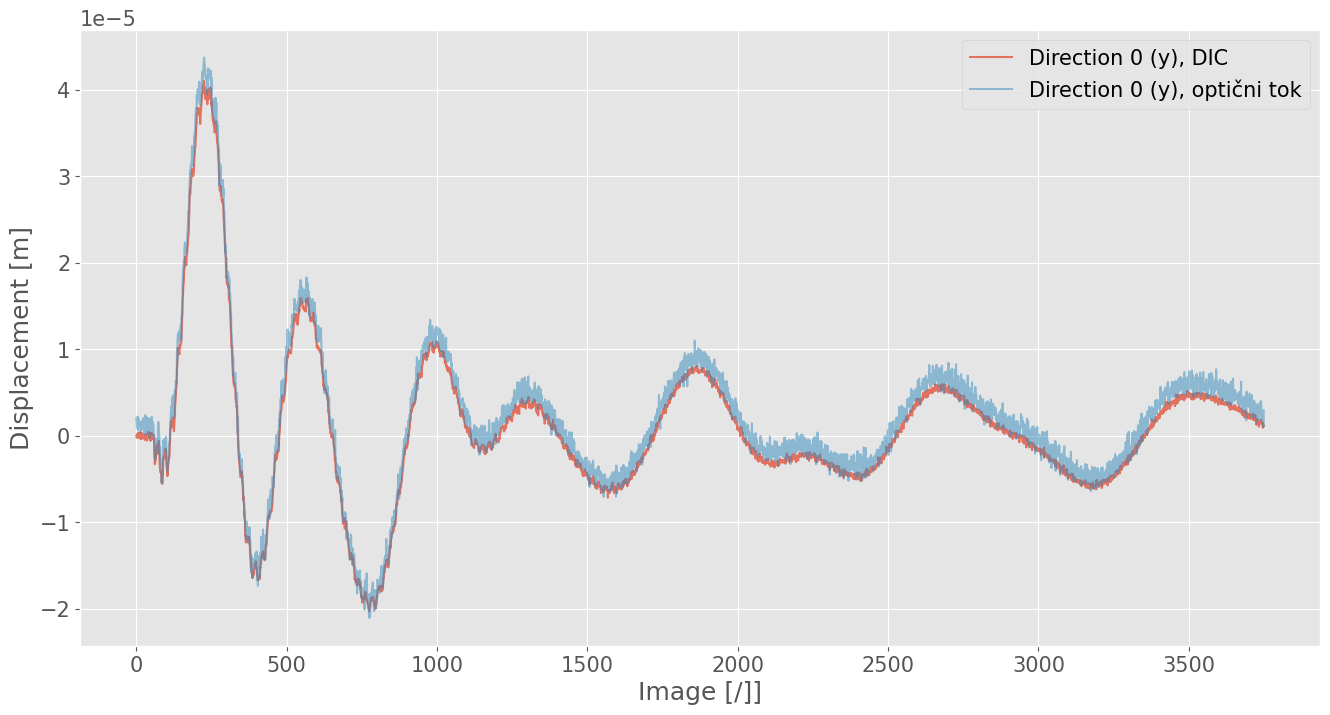

In [61]:
fig, ax = plt.subplots()
ax.plot(displacements_lk[location, :, 0], label='Direction 0 (y), DIC', alpha=0.75)
ax.plot(displacements[location, :, 0], label='Direction 0 (y), optični tok', alpha=0.5);
ax.set_xlabel('Image [/]]')
ax.set_ylabel('Displacement [m]')
plt.legend()

In [69]:
displacements = displacements_lk

## Izračun FRF

Izračun amplitudnih spektrov pomikov:

In [70]:
N = int(video.info['Total Frame'])
dt = 1/int(video.info['Record Rate(fps)'])
1/dt

15000.0

In [71]:
T = dt*N
T

0.25

In [72]:
upper_f_limit = 4000 # zgornja frekvenčna meja, ki nas zanima

In [74]:
freq_cam = np.fft.rfftfreq(N, dt)
fft_cam = np.fft.rfft(displacements[:, :, 0], N) * 2 / N 

Opazujemo le frekvence pod mejo `upper_f_limit` Hz:

In [75]:
fft_cam = np.copy(fft_cam[:, freq_cam<upper_f_limit])
freq_cam = np.copy(freq_cam[freq_cam<upper_f_limit])

Silo vzbujanja smo merili s silomerom.

Da lahko meritiv kombiniaramo, je pomembna **ujemajoča frekvenčna ločljivost**! 

Tudi tukaj se omejimo do `upper_f_limit`:

In [77]:
lvm = lvm_read.read(lvm_fname)
force = lvm[0]['data'][:-30, 1] # 30 predvzorcev
N = len(force)//4 # dolžina shranjenega videa je 0.25 s
dt = lvm[0]['Delta_X'][1]

fft_force = np.fft.rfft(force, N) *2/N
freq_force = np.fft.rfftfreq(N, dt)

fft_force = np.copy(fft_force[freq_force<upper_f_limit])
freq_force = np.copy(freq_force[freq_force<upper_f_limit])

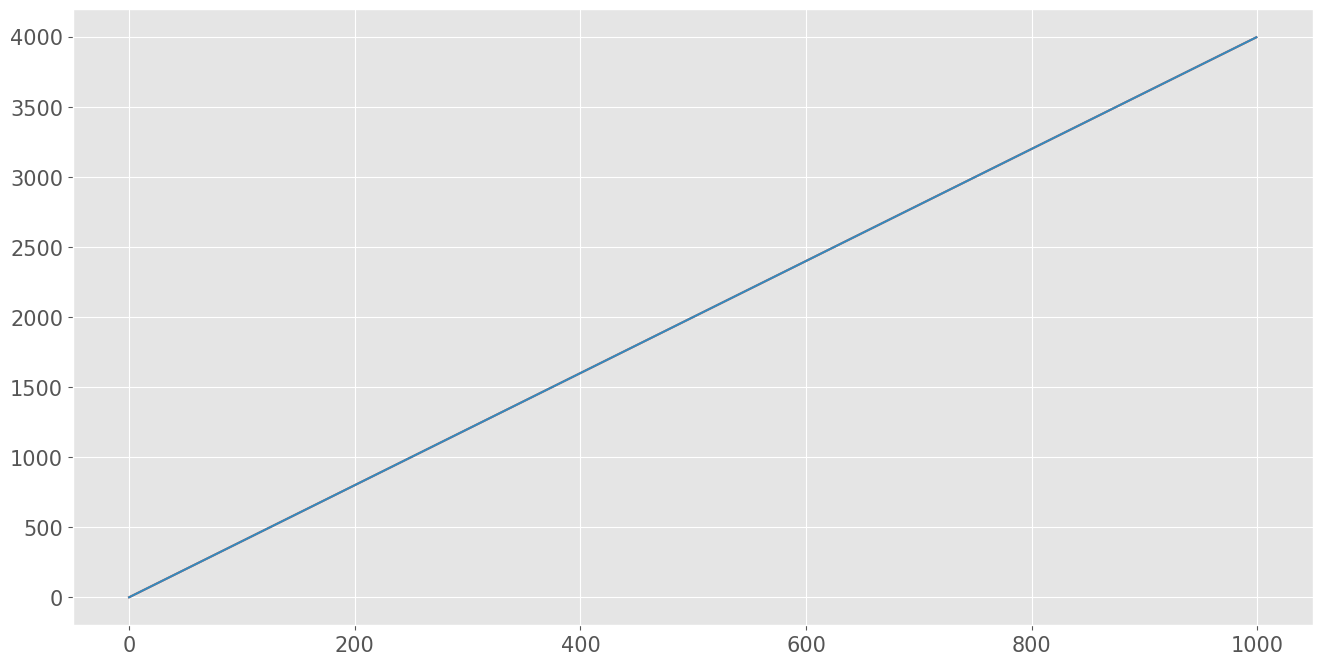

In [78]:
plt.plot(freq_cam)
plt.plot(freq_force)

Ker smo zajeli le en segment ne moremo uporabiti natančnejše cneilke FRF:

In [79]:
frf_cam = fft_cam/fft_force 

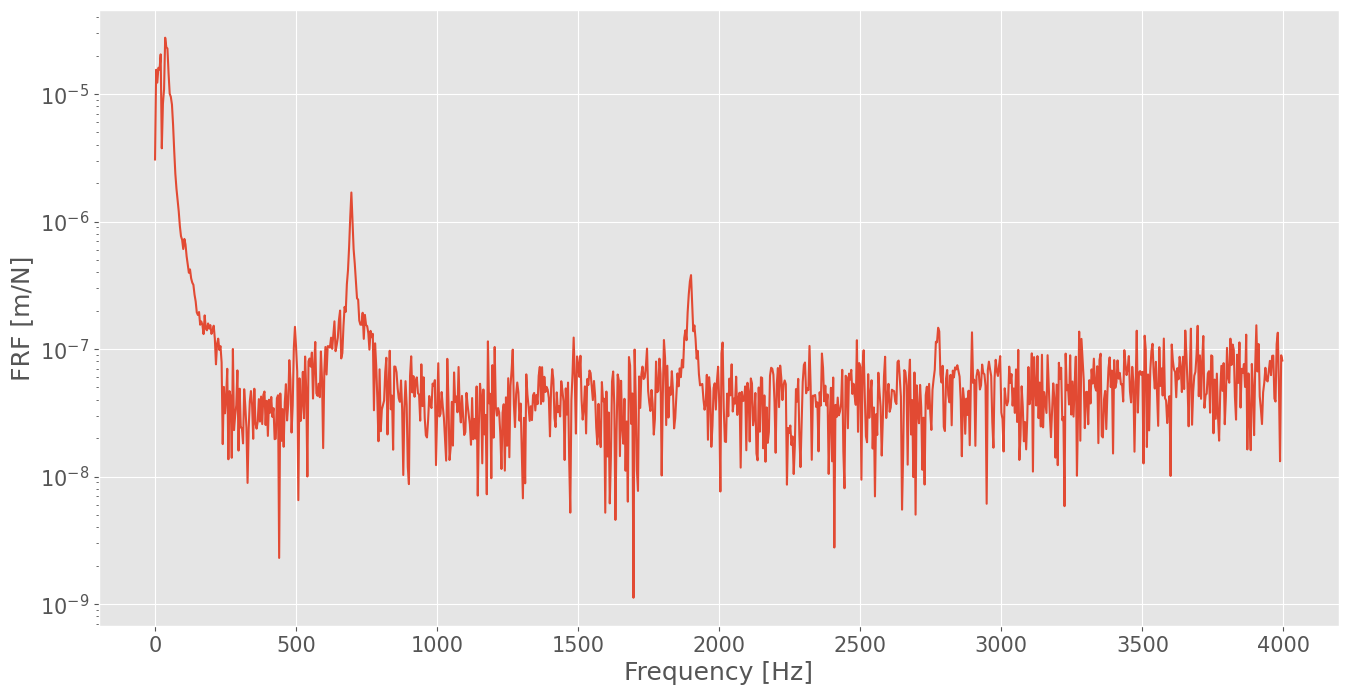

In [80]:
plt.figure()
plt.semilogy(freq_cam, np.abs(frf_cam[točka]));
plt.xlabel('Frequency [Hz]')
plt.ylabel('FRF [m/N]');

## Eskperimentalna modalna analiza (samo slikovna meritev):

Za eksperimentalno modalno analizo uporabimo paket [``sdypy-EMA``][1].

[1]: https://github.com/sdypy/sdypy

In [81]:
cam = pyEMA.Model(frf_cam, freq_cam, pol_order_high=75, upper=upper_f_limit)

Izračun polov modela frekvenčne prenosne funkcije:

In [82]:
cam.get_poles(show_progress=True)

  0%|                                                                        | 0/75 [00:00<?, ?it/s]/mnt/data/pedagoško/_Procesiranje signalov/_VAJE/_PREDLOGE/.venv/lib/python3.13/site-packages/sdypy/EMA/EMA.py:454: RuntimeWarning: invalid value encountered in log
  poles = -np.log(sr) / self.sampling_time
100%|███████████████████████████████████████████████████████████████| 75/75 [00:01<00:00, 44.74it/s]


Izbrati moramo pole, ki se zdijo fizikalno smiselni (stabilni).

In [83]:
cam.select_poles()

100%|██████████████████████████████████████████████████████████████| 75/75 [00:00<00:00, 259.83it/s]


<Figure size 1600x800 with 0 Axes>

In [84]:
cam.print_modal_data()

   Nat. f.      Damping
-----------------------
1)  695.4	0.0016
2) 1898.0	0.0004


Za rekonstrukcijo modela FRF uporabimo metodo LSFD:

In [86]:
frf_rec, shapes_cam = cam.get_constants(FRF_ind='all')

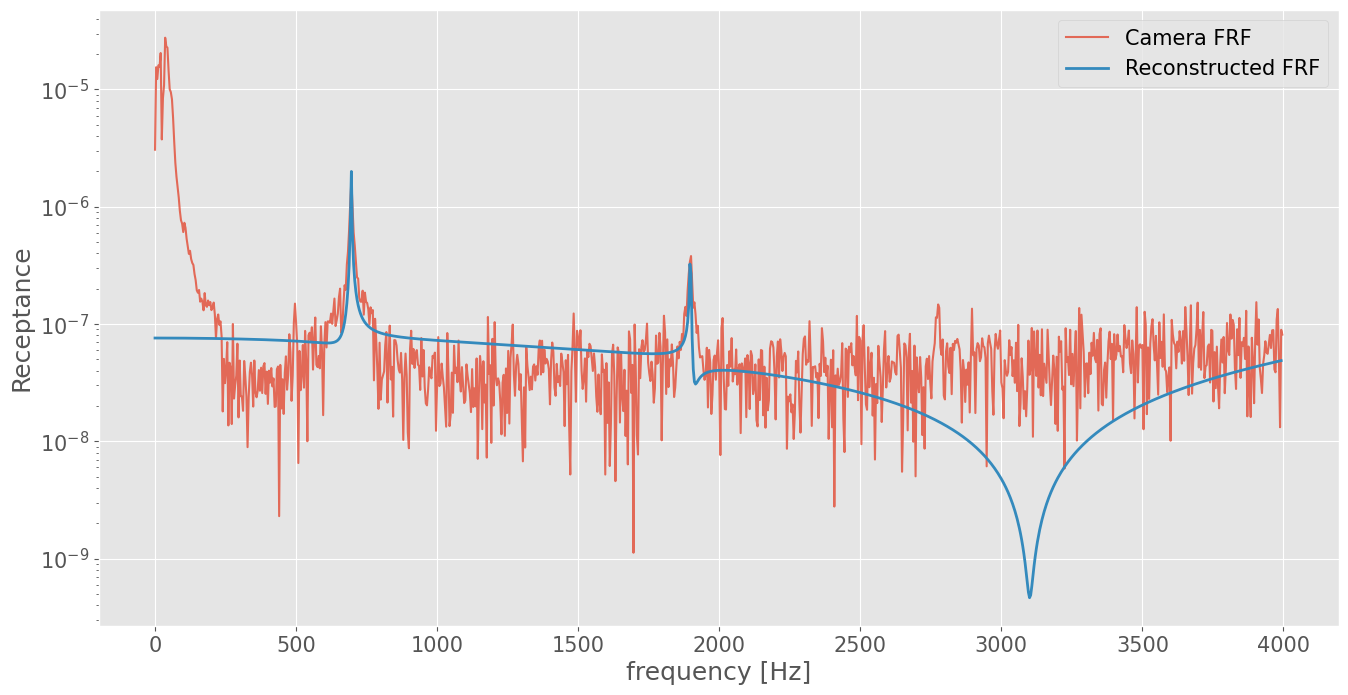

In [87]:
fig, ax = plt.subplots()
ax.semilogy(freq_cam, np.abs(frf_cam[točka]), label='Camera FRF', alpha=0.8)
ax.semilogy(freq_cam[:-1], np.abs(frf_rec[točka]), label='Reconstructed FRF', lw=2)
ax.set_xlabel('frequency [Hz]')
ax.set_ylabel('Receptance')
plt.legend();

/mnt/data/pedagoško/_Procesiranje signalov/_VAJE/_PREDLOGE/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/data/pedagoško/_Procesiranje signalov/_VAJE/_PREDLOGE/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


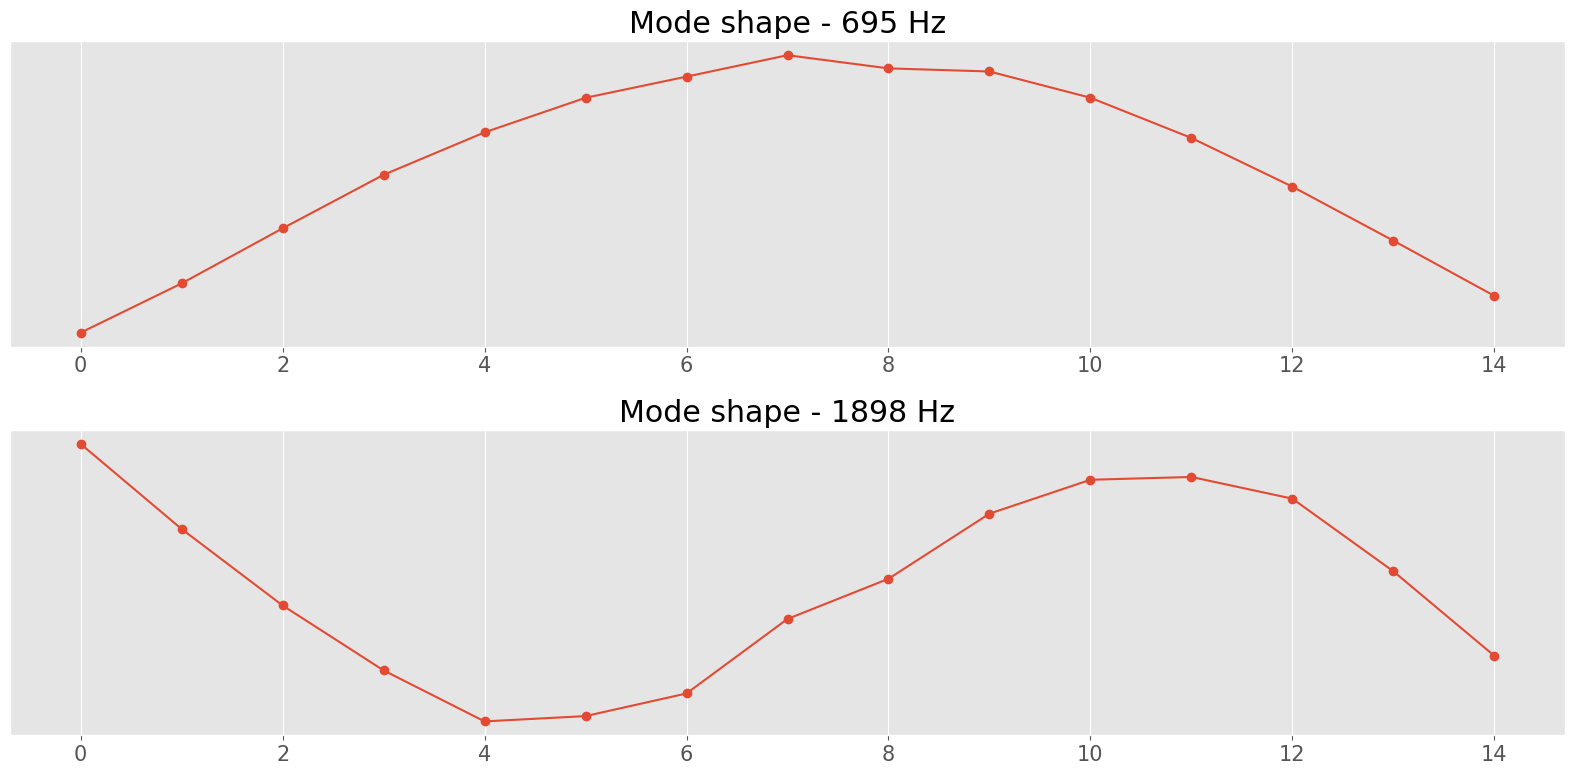

In [88]:
fig, ax = plt.subplots(shapes_cam.shape[1])
for i, a in enumerate(ax):
    plot_mode_shape(shapes_cam[:, i], axis=a, frequency=cam.nat_freq[i])

## Primerjava z meritivjo pospeškomera

Pri hibridni metodi kombiniramo pomike s slik z visoko prostorsko ločljivostjo in meritve pospeška z visoko natančnostjo:

In [89]:
hyb_acc = lvm[0]['data'][:-30, 0] * 9.81 # pospeškomer

Za oceno FRF lahk uporabimo paket [``pyFRF``][1]

[1]: https://pypi.org/project/pyFRF/

In [90]:
frf_ = pyFRF.FRF(
    sampling_freq=int(np.round(1/dt)),
    exc=force,
    resp=hyb_acc,
    exc_type='f',
    resp_type='a')

/mnt/data/pedagoško/_Procesiranje signalov/_VAJE/_PREDLOGE/.venv/lib/python3.13/site-packages/pyFRF.py:421: RuntimeWarning: divide by zero encountered in divide
  self.frf_conversion = np.power(-1.j / self.get_w_axis(), 2)
/mnt/data/pedagoško/_Procesiranje signalov/_VAJE/_PREDLOGE/.venv/lib/python3.13/site-packages/pyFRF.py:421: RuntimeWarning: invalid value encountered in divide
  self.frf_conversion = np.power(-1.j / self.get_w_axis(), 2)


Opazujemo le frekvenčno območj do `upper_f_limit` Hz:

In [91]:
freq_acc = frf_.get_f_axis()
frf_acc = frf_.get_FRF(form='accelerance')[0, 0]

frf_acc = frf_acc[freq_acc<upper_f_limit]
freq_acc = freq_acc[freq_acc<upper_f_limit]

Pospeškomer je bil nameščen v točki z indeksom 3:

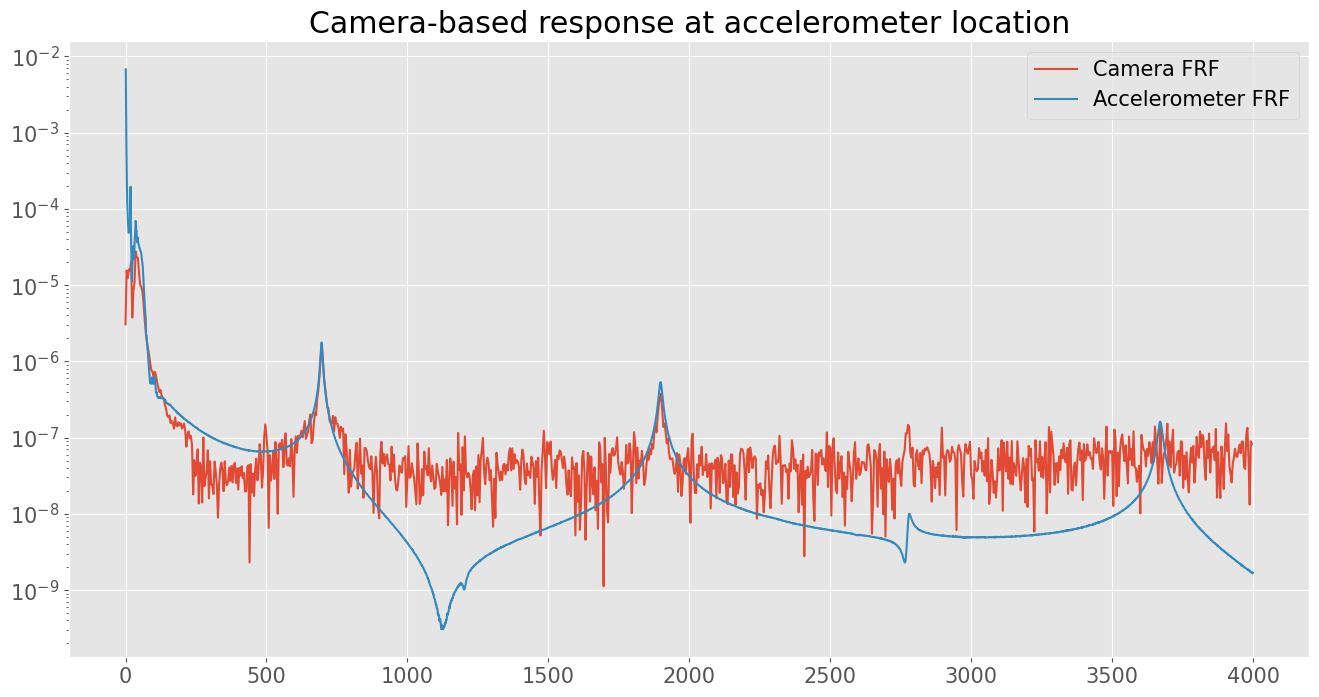

In [92]:
fig, ax = plt.subplots()
ax.semilogy(freq_cam, np.abs(frf_cam[točka]), label='Camera FRF')
ax.semilogy(freq_acc, np.abs(frf_acc / -(2*np.pi*freq_acc)**2), label='Accelerometer FRF')
ax.set_title('Camera-based response at accelerometer location')
plt.legend();